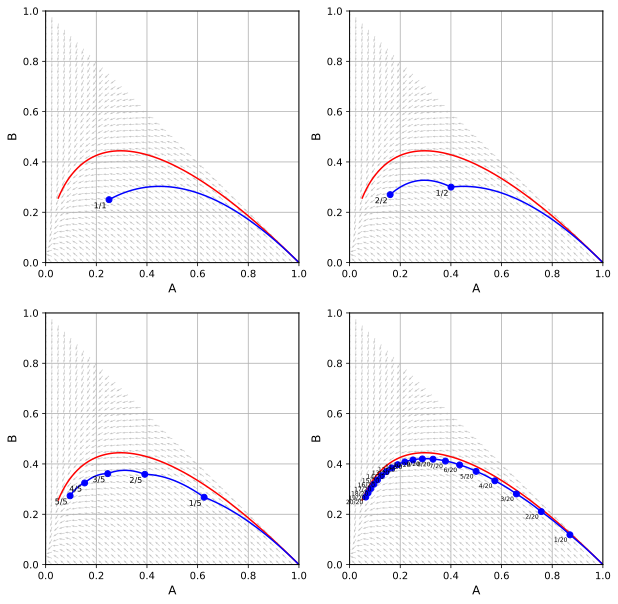

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import chbe444umd as des

# Define reaction system
sysABC = des.ReactionSystem(
    component_ids=('A', 'B', 'C'),
    component_names={'A': 'A', 'B': 'B', 'C': 'C'},
    axes={'A': 0, 'B': 1},
    h_lim=[0, 1],
    v_lim=[0, 1],
    reactions=('r1', 'r2'),
    stoich={'r1': {'A': -1, 'B': 1},
            'r2': {'B': -1, 'C': 1}},
    kinetics={'r1': lambda C: 3 * C['A'],
              'r2': lambda C: 2 * C['B']},
    inequality=lambda C: C['A'] + C['B'] - 1
)

# Create a (2, 2) grid of four subplots
%config InlineBackend.figure_format='svg'
%matplotlib inline
figure, axes = plt.subplots(figsize=(10, 10), nrows=2, ncols=2)

# Plot rate field on all four subplots
for i in range(2):
    for j in range(2):
        fig, ax, _ = sysABC.plot_rate_field(ax=axes[i, j],
                                            fsize=6,
                                            n_vec=41,
                                            arrow_scale=41)

# Simulate PFR with tau=1 from fresh feed of [1, 0] on all subplots
pfr = des.Reactor(name='PFR', flow_type='plug', feed=[1, 0], time=1)

for i in range(2):
    for j in range(2):
        pfr.simulate(system=sysABC, ax=axes[i, j])

cstrs = []

# 1st subplot: single cstr with tau=1 (same tau as the pfr)
# 2nd subplot: 2-cstr series, each with tau=0.5 (half the tau of the pfr)
# 3rd subplot: 10-cstr series, each with tau=0.1 (1/10 of the tau of the pfr)
# 4th subplot: 100-cstr series, each with tau=0.01 (1/100 of the tau of the pfr)
for n in [1, 2, 5, 20]:
    match n:
        case 1:
            ii, jj = 0, 0
        case 2:
            ii, jj = 0, 1
        case 5:
            ii, jj = 1, 0
        case 20:
            ii, jj = 1, 1

    for k in range(n):
        if k == 0:
            fd = [1, 0]

        cstr = des.Reactor(flow_type='mixed', feed=fd, time=1 / n)
        cstr.x = []
        cstr.y = []
        cstr.tau = []
        cstr.xy = []
        cstr.simulate(system=sysABC, ax=axes[ii, jj])

        xx = cstr.x[~np.isnan(cstr.tau)]
        yy = cstr.y[~np.isnan(cstr.tau)]
        tt = cstr.tau[~np.isnan(cstr.tau)]

        i = np.argmax(tt)
        ttt = tt[i]
        cstr.plot_point(axes[ii, jj], tau=ttt, annotate=False)
        xxx = xx[i]
        yyy = yy[i]

        string = str(k + 1) + '/' + str(n)
        if n <= 5:
            fontsize = 8
        else:
            fontsize = 6
        axes[ii, jj].text(xxx-0.01, yyy-0.01, string,
                          ha='right', va='top', fontsize=fontsize)

        mask = ~np.isnan(cstr.x) & ~np.isnan(cstr.y)
        idx = np.argmin(cstr.x[mask])
        fd = [cstr.x[mask][idx], cstr.y[mask][idx]]

In [2]:
fig.savefig('cstr_series.svg', format='svg', bbox_inches='tight', pad_inches=0)